In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import LogLocator
import os
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import matplotlib.gridspec as gridspec
import matplotlib as mpl
from tqdm.notebook import tqdm
from scipy.stats import spearmanr

# Configure font sizes.
TICK_SIZE = 6
SMALL_SIZE = 7
MEDIUM_SIZE = 8
BIGGER_SIZE = 11
plt.rc("font", size=SMALL_SIZE)  # controls default text sizes
plt.rc("axes", titlesize=MEDIUM_SIZE)  # fontsize of the axes title
plt.rc("axes", labelsize=MEDIUM_SIZE)  # fontsize of the x and y labels
plt.rc("xtick", labelsize=TICK_SIZE)  # fontsize of the tick labels
plt.rc("ytick", labelsize=TICK_SIZE)  # fontsize of the tick labels
plt.rc("legend", fontsize=SMALL_SIZE)  # legend fontsize
plt.rc("figure", titlesize=BIGGER_SIZE)  # fontsize of the figure title

MARKERSIZE = 3
LINEWIDTH = 0.5
plt.rc("lines", markersize=MARKERSIZE, linewidth=LINEWIDTH)
plt.rc("grid", linewidth=0.5)
plt.rc("grid", alpha=0.5)

# directory to store our figures
if "figures" not in os.listdir():
    os.mkdir("figures")
    
# dataset descriptions (prettified)
dataset_descs = {
    "acs" : "ACS", "alphafold" : "AlphaFold", "bbh+gpqa+ifeval+math+musr" : "BBH+GPQA+(...)",
    "bodmas" : "BODMAS", "hiv" : "HIV", "mmlu-pro" : "MMLU-Pro", "pew" : "Pew", "ulb" : "ULB"
}

# 1. How does PAI compare to SAI, PPI, and Uniform?

In [2]:
# load in our log file
summaries = pd.read_csv("summaries/summaries.csv")

# what datasets are we working with?
datasets = [d for d in sorted(summaries.dataset.unique()) if d != "ulb"]

# what markers are we using
markers = {"pai" : "o", "sai" : "^", "ppi" : "x", "uniform" : "s", "ppat" : "*"}

# colorblind friendly colors: https://gist.github.com/thriveth/8560036
colors = {
    "pai" : "#377eb8", "sai" : "#ff7f00", "ppi" : "#4daf4a", 
    "uniform" : "#f781bf", "ppat" : "#a65628"
}

## 1(a) ESS multipliers w.r.t. uniform for PAI, SAI, PPI, and Uniform.

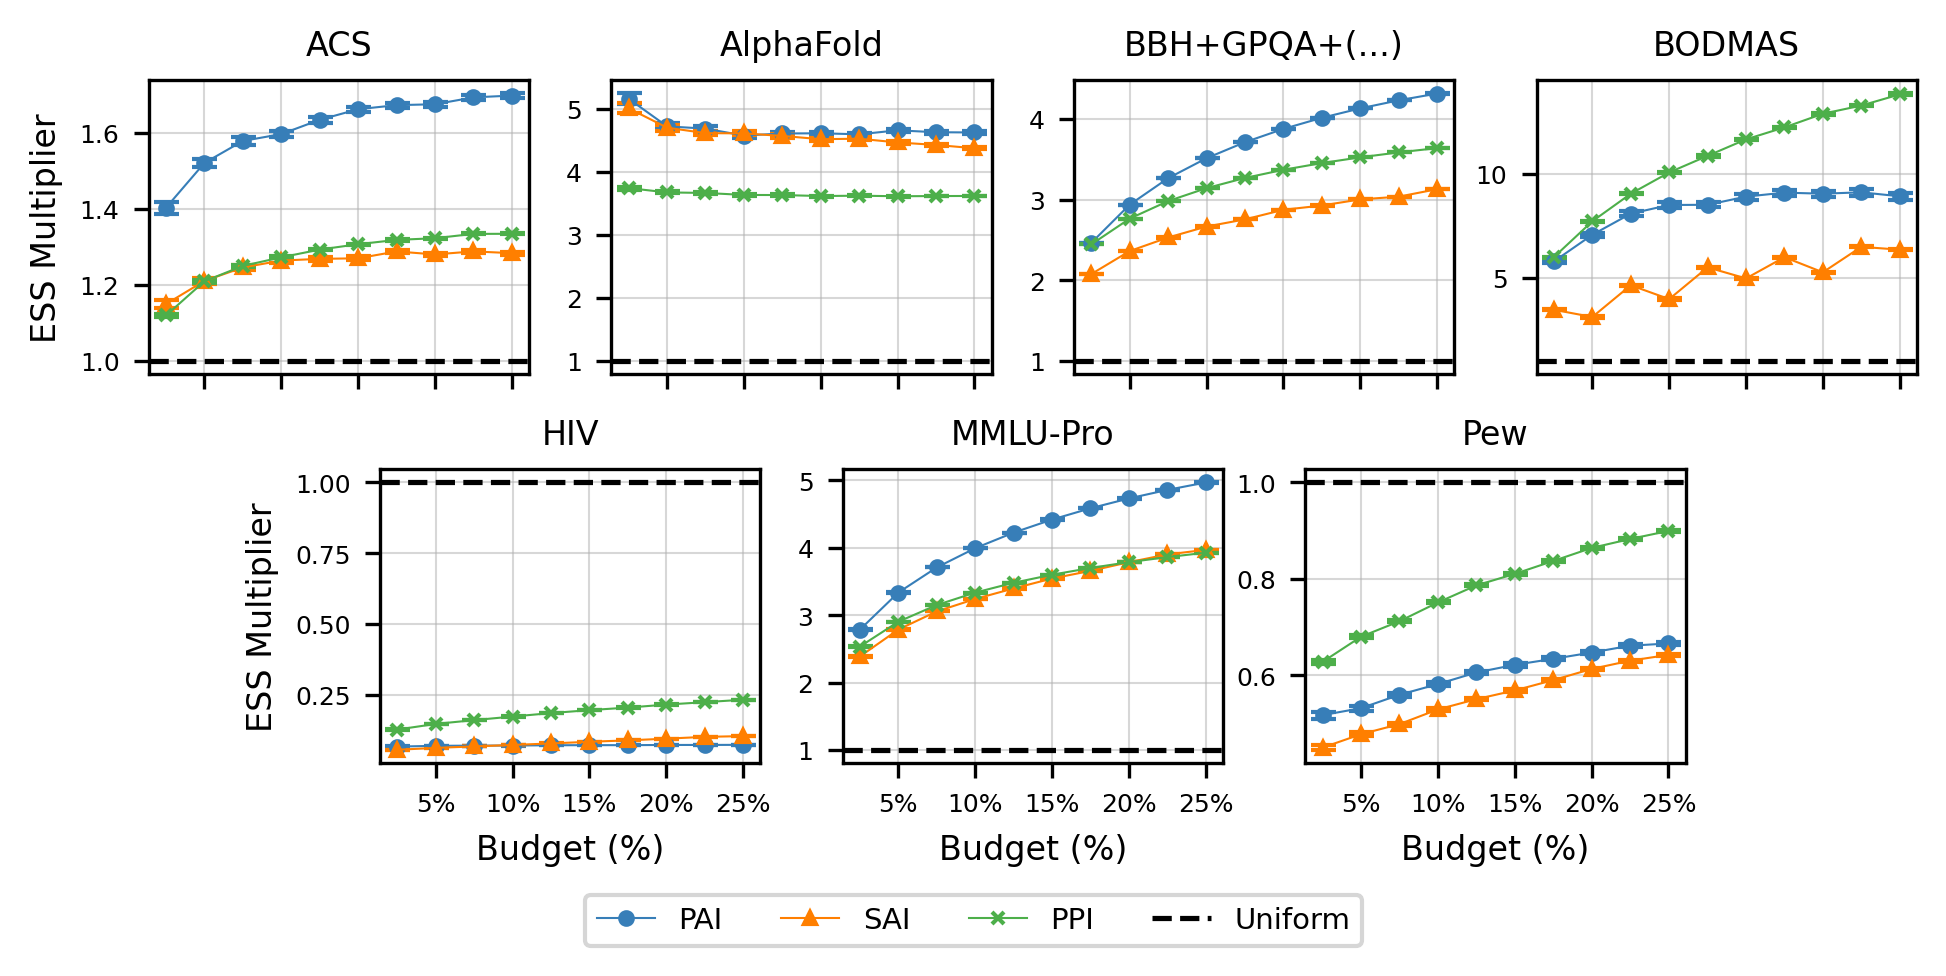

In [3]:
'''
Note on ULB: coverage at 2.5% is 63.4% for PPAT, 64.6% for PAI, 
82.0% for SAI, 92.1% for PPI, and 92.1% for Uniform.
'''
# create a subplot grid for 7 of the 8 datasets
fig, axs = plt.subplot_mosaic(figsize=(6.5, 3), dpi=300, sharex=True,
    mosaic='''
    AABBCCDD
    .EEFFGG.
    '''
)

# go thru each of our non-DQ datasets and plot ESS multipliers
for i, ax_key in enumerate(axs.keys()):
    
    # grid it up for readability + say what dataset it is
    axs[ax_key].grid(alpha=0.5)
    axs[ax_key].set_title(dataset_descs[datasets[i]])
    if i > 3:
        axs[ax_key].set_xlabel("Budget (%)")
    if i == 0 or i == 4:
        axs[ax_key].set_ylabel("ESS Multiplier")
    
    # always need to put a red line for uniform would be
    axs[ax_key].axhline(y=1.0, linestyle="--", color="black", linewidth=1.25)
    
    # iterate thru each of our methods
    for j, method in enumerate(["pai", "sai", "ppi"]):
        
        # make our query for this dataset and method
        q = summaries.query(f"dataset == '{datasets[i]}' and method == '{method}'")
        axs[ax_key].errorbar(
            q.budget, q.ess_multiplier_mean, yerr=q.ess_multiplier_sem,
            capsize=MARKERSIZE, capthick=1.0,
            marker=markers[method], color=colors[method])
        axs[ax_key].set_xticks([0.05, 0.10, 0.15, 0.20, 0.25])
        axs[ax_key].set_xticklabels(["5%", "10%", "15%", "20%", "25%"])
    
# custom legend
handles = [
    Line2D([], [], marker=markers[method], color=colors[method], label=method.upper())
    for method in ["pai", "sai", "ppi"]
] + [Line2D([], [], linestyle="--", linewidth=1.25, color="black", label="Uniform")]
fig.legend(handles=handles, ncol=4, loc="lower center", bbox_to_anchor=(0.5, -0.07))
    
# beautify at the end
plt.tight_layout(w_pad=-1.25, h_pad=1.)
plt.savefig("figures/pai_sai_ppi_uniform_ess.pdf", facecolor="white", bbox_inches="tight")
plt.show()

In [4]:
# check win rates against SAI on AlphaFold
(summaries.query("dataset == 'alphafold' and method == 'pai'").ess_multiplier_mean.values\
> summaries.query("dataset == 'alphafold' and method == 'sai'").ess_multiplier_mean.values).mean()

0.9

In [5]:
# check win rates against SAI on HIV
(summaries.query("dataset == 'hiv' and method == 'pai'").ess_multiplier_mean.values\
> summaries.query("dataset == 'hiv' and method == 'sai'").ess_multiplier_mean.values).mean()

0.3

## 1(b) Coverages for PAI, SAI, PPI, Uniform, PPAT

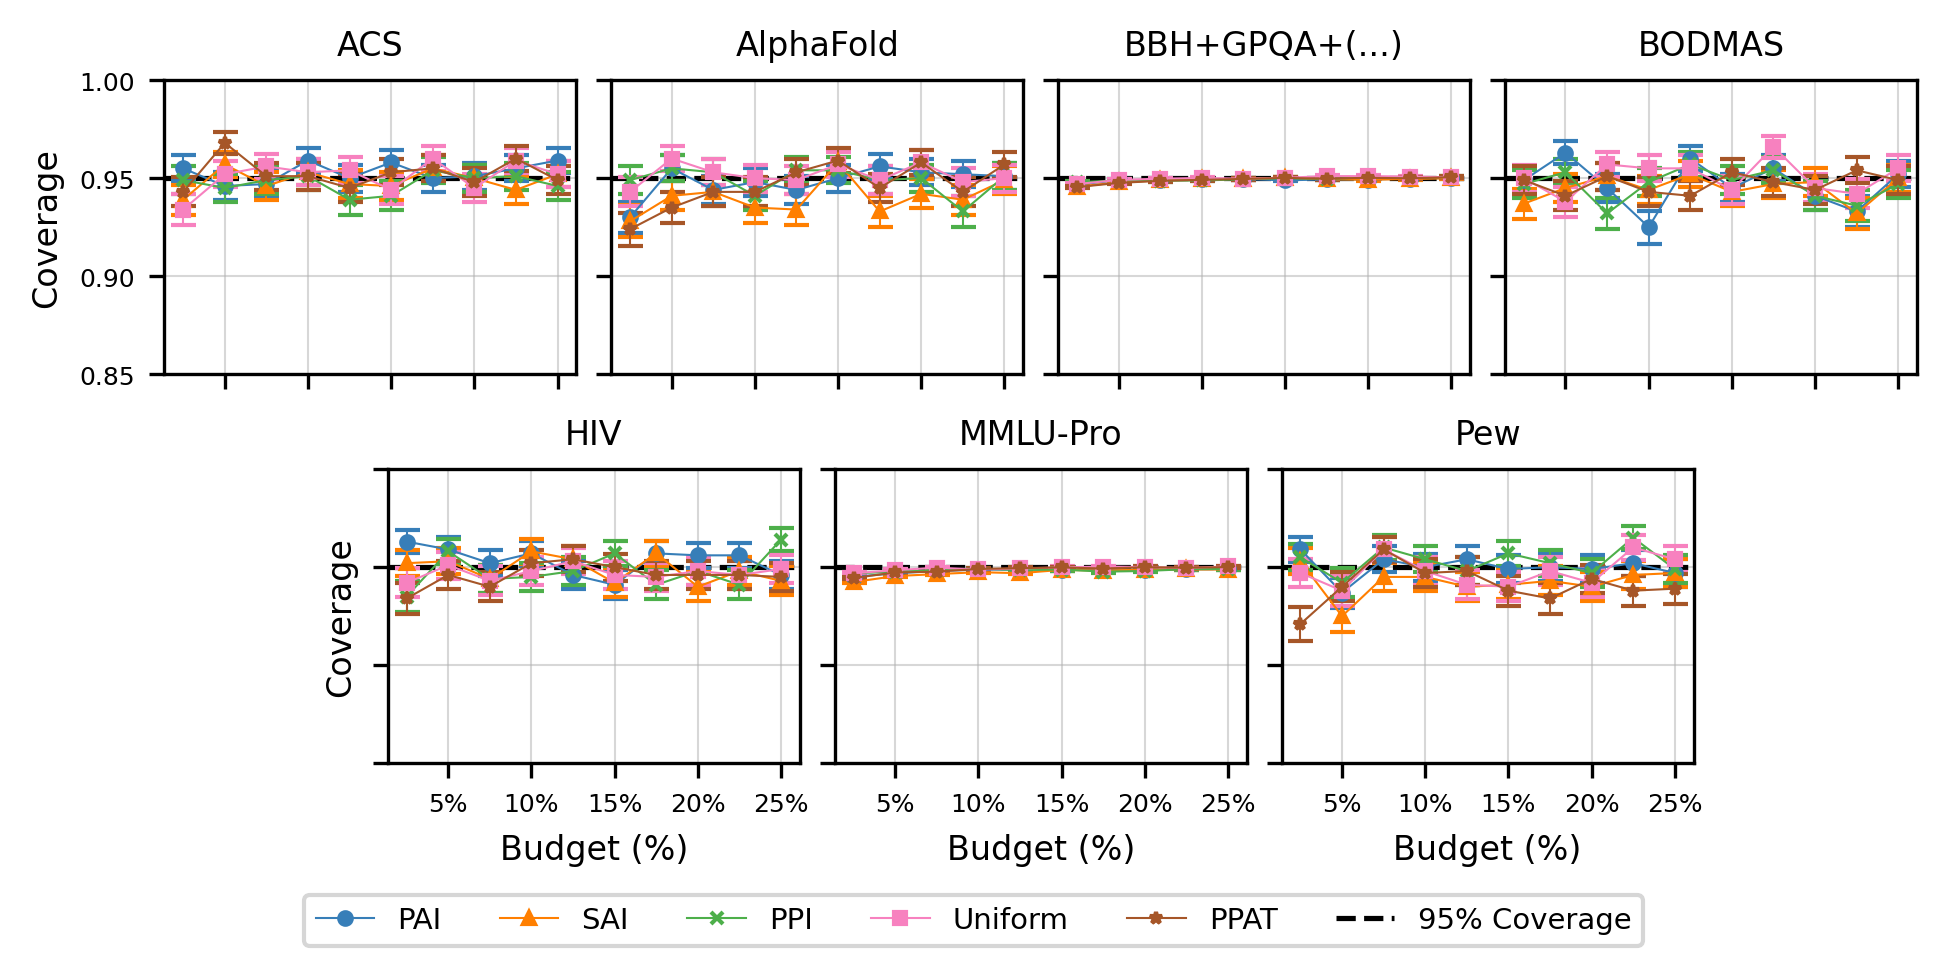

In [6]:
# create a subplot grid for 7 of the 8 datasets
fig, axs = plt.subplot_mosaic(figsize=(6.5, 3), dpi=300, sharex=True, sharey=True,
    mosaic='''
    AABBCCDD
    .EEFFGG.
    '''
)

# also load in the PPAT summaries because we want to plot their coverages
ppat_summaries = pd.read_csv("summaries/ppat_comparison_summaries.csv")

# go thru each of our non-DQ datasets and plot ESS multipliers
for i, ax_key in enumerate(axs.keys()):
    
    # grid it up for readability + say what dataset it is
    axs[ax_key].grid(alpha=0.5)
    axs[ax_key].set_title(dataset_descs[datasets[i]])
    if i > 3:
        axs[ax_key].set_xlabel("Budget (%)")
    if i == 0 or i == 4:
        axs[ax_key].set_ylabel("Coverage")
    
    # always need to put a black line for where our target coverage is
    axs[ax_key].axhline(y=0.95, linestyle="--", color="black", linewidth=1.25)
    axs[ax_key].set_ylim(bottom=0.85, top=1.0)
    
    # iterate thru each of our standard methods
    for j, method in enumerate(["pai", "sai", "ppi", "uniform"]):
        
        # make our query for this dataset and method
        q = summaries.query(f"dataset == '{datasets[i]}' and method == '{method}'")
        axs[ax_key].errorbar(
            q.budget, q.coverage_mean, yerr=q.coverage_sem,
            capsize=MARKERSIZE, capthick=1.0,
            marker=markers[method], color=colors[method])
    
    # also show PPAT results
    q = ppat_summaries.query(f"method == 'ppat' and dataset == '{datasets[i]}'")
    axs[ax_key].errorbar(
        q.budget, q.coverage_mean, yerr=q.coverage_sem,
        capsize=MARKERSIZE, capthick=1.0,
        marker=markers["ppat"], color=colors["ppat"])
    
    # set the ticks at the end
    axs[ax_key].set_xticks([0.05, 0.10, 0.15, 0.20, 0.25])
    axs[ax_key].set_xticklabels(["5%", "10%", "15%", "20%", "25%"])
    
# custom legend
handles = [
    Line2D([], [], marker=markers[method], color=colors[method], 
           label=method.upper() if method != "uniform" else "Uniform")
    for method in ["pai", "sai", "ppi", "uniform", "ppat"]
] + [Line2D([], [], linestyle="--", linewidth=1.25, color="black", label="95% Coverage")]
fig.legend(handles=handles, ncol=6, loc="lower center", bbox_to_anchor=(0.5, -0.07))
    
# beautify at the end
plt.tight_layout(w_pad=-1, h_pad=1.)
plt.savefig("figures/all_coverages.pdf", facecolor="white", bbox_inches="tight")
plt.show()

# 2. Do our results against SAI/BAI corroborate our theory?

In [7]:
# load in b^2 diagnostic for SAI/BAI comparisons
b2s = pd.read_csv("diagnostics/b2s.csv").query("dataset != 'ulb'").reset_index(drop=True)\
.replace("llm_evals/mmlu-pro", "mmlu-pro")\
.replace("llm_evals/bbh+gpqa+ifeval+math+musr", "bbh+gpqa+ifeval+math+musr")

# load in our sai comparison summaries
sai_comparisons = pd.read_csv("summaries/sai_comparison_summaries.csv")

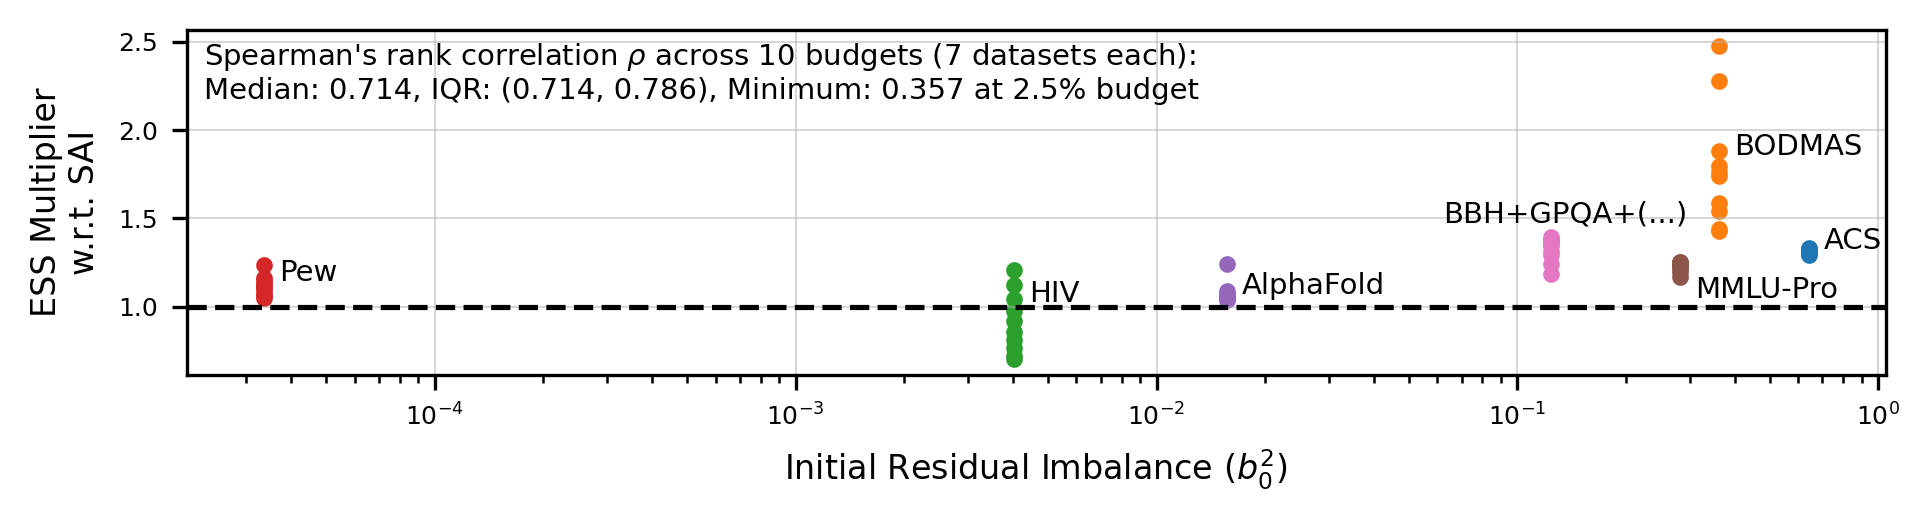

In [8]:
# we need to plot b2 vs. ESS multipliers vs. SAI
fig, ax = plt.subplots(figsize=(6.5, 1.75), dpi=300)
ax.grid(); ax.set_xlabel("Initial Residual Imbalance ($b_0^2$)"); ax.set_ylabel("ESS Multiplier\nw.r.t. SAI")

# store the b^2 and the corresponding ESS multipliers relative to SAI
X_b2, y_b2 = [], []

# go thru all our datasets (except for ULB)
for dataset in b2s.dataset.unique():
    
    # a. get the b^2 diagnostic
    b2 = b2s.query(f"dataset == '{dataset}'").b2.values
    ess_multipliers = sai_comparisons.query(
        f"dataset == '{dataset}' and method == 'pai'").ess_multiplier_wrt_sai_mean.values
    
    # b. scatter plot b^2 against ESS multipliers w.r.t. SAI + annotate
    ax.scatter([b2[0]] * len(ess_multipliers), ess_multipliers)
    if dataset == "bbh+gpqa+ifeval+math+musr":
        delta_x = 0.5; delta_y = 0.1
    elif dataset == "mmlu-pro":
        delta_x, delta_y = 1.1, -0.2
    else:
        delta_x, delta_y = 1.1, 0.0
    ax.annotate(text=dataset_descs[dataset], 
                xy=(b2[0] * delta_x, np.quantile(ess_multipliers, 0.75) + delta_y))
    
    # c. add to our list
    X_b2.append([b2[0]] * len(ess_multipliers))
    y_b2.append(ess_multipliers)
    
# also compute some Spearman coefficients across budgets
X_b2, y_b2 = np.array(X_b2), np.array(y_b2)
spearman_vals = sorted([spearmanr(X_b2[:,i], y_b2[:,i]).statistic for i in range(10)])
    
# annotate the spearman correlation ranges
r = "r"
ax.annotate(text=f"Spearman's rank correlation $\{r}ho$ across 10 budgets (7 datasets each):\nMedian: {np.median(spearman_vals):.3f}, " + \
            f"IQR: ({np.quantile(spearman_vals, 0.25):.3f}, {np.quantile(spearman_vals, 0.75):.3f}), " + \
            f"Minimum: {np.min(spearman_vals):.3f} at 2.5% budget", 
            xy=(0.01, 0.8), xycoords="axes fraction", fontsize=SMALL_SIZE)

# beautify
ax.set_xscale("log")
ax.axhline(y=1.0, linestyle="--", color="black", linewidth=1.25)
plt.tight_layout()
plt.savefig("figures/sai_theory_corroboration.pdf", facecolor="white", bbox_inches="tight")
plt.show()

# 3. How do we compare against PAI (with-replacement)?

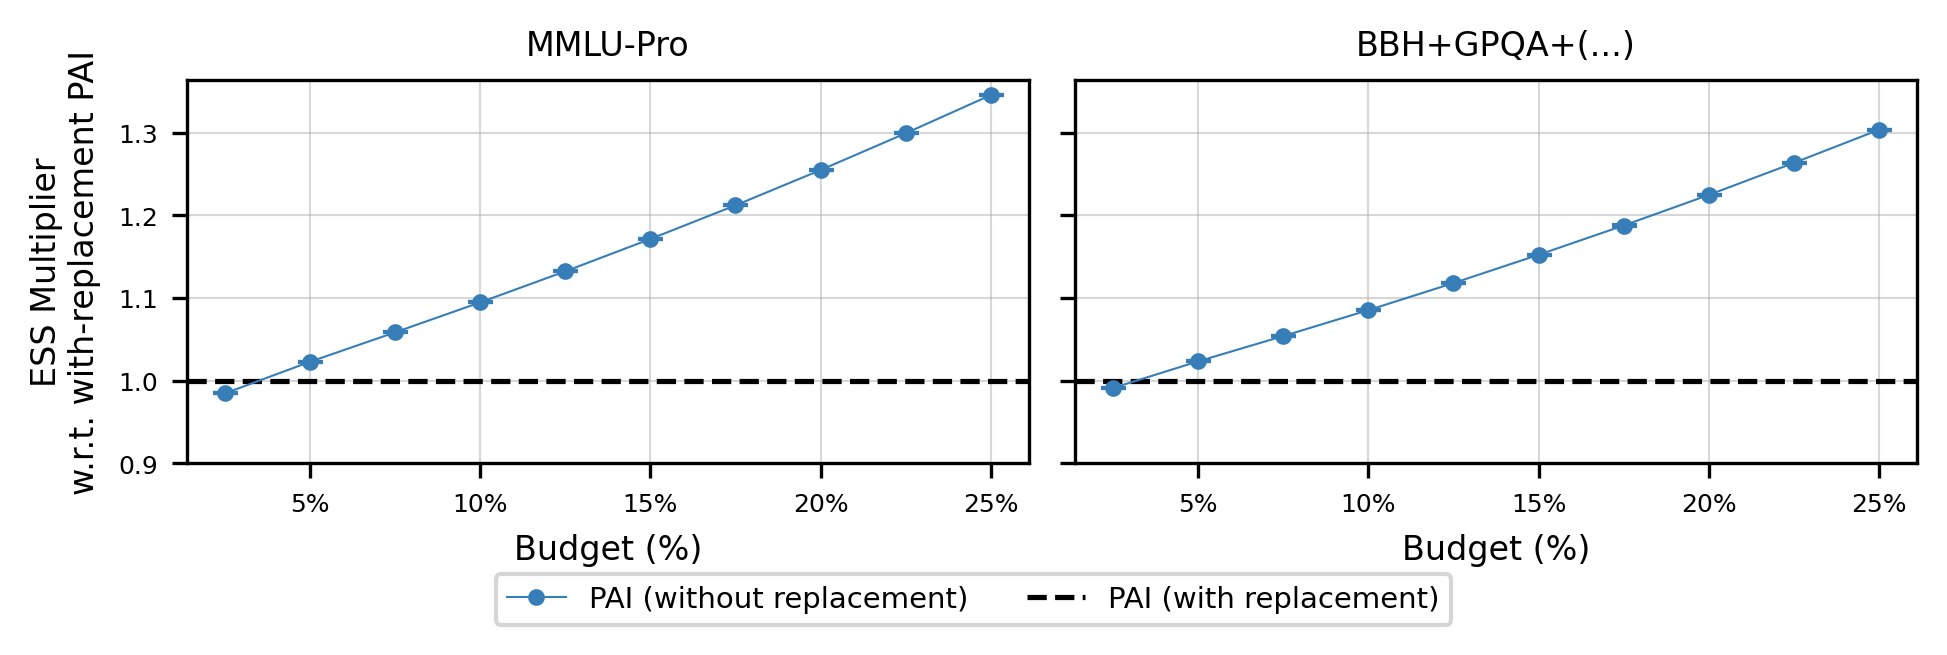

In [9]:
# load in our summary files
llm_evals_ablation_summaries = pd.read_csv("summaries/llm_evals_ablation_summaries.csv")

# only need to do the 2 LLM evaluation suites
fig, ax = plt.subplots(1, 2, dpi=300, figsize=(6.5, 2), sharex=True, sharey=True)

# go thru each dataset, show how much we win by
for i, dataset in enumerate(["mmlu-pro", "bbh+gpqa+ifeval+math+musr"]):
    
    # make our query + mark our plot
    q = llm_evals_ablation_summaries.query(f"dataset == '{dataset}' and method == 'pai'")
    ax[i].errorbar(
        q.budget, q.ess_multiplier_wrt_wr_mean, yerr=q.ess_multiplier_wrt_wr_sem,
        capsize=MARKERSIZE, capthick=1.0,
        marker=markers["pai"], color=colors["pai"])
    
    # mark where with-replacement PAI should be
    ax[i].axhline(y=1.0, linestyle="--", color="black", linewidth=1.25)
    
    # beautify + labeling
    ax[i].grid(alpha=0.5)
    ax[i].set_xlabel("Budget (%)")
    ax[i].set_xticks([0.05, 0.1, 0.15, 0.2, 0.25])
    ax[i].set_xticklabels(["5%", "10%", "15%", "20%", "25%"])
    ax[i].set_ylim(bottom=0.9)
    ax[i].set_title(dataset_descs[dataset])

# custom legend
handles = [
    Line2D([], [], marker=markers["pai"], color=colors["pai"], label="PAI (without replacement)")
] + [Line2D([], [], linestyle="--", linewidth=1.25, color="black", label="PAI (with replacement)")]
fig.legend(handles=handles, ncol=2, loc="lower center", bbox_to_anchor=(0.5, -0.07))
    
# beautify
ax[0].set_ylabel("ESS Multiplier\nw.r.t. with-replacement PAI")
plt.tight_layout()
plt.savefig("figures/pai_wr_vs_without_r.pdf", facecolor="white", bbox_inches="tight")
plt.show()

# 4. How do we compare against PPAT in a head-to-head?

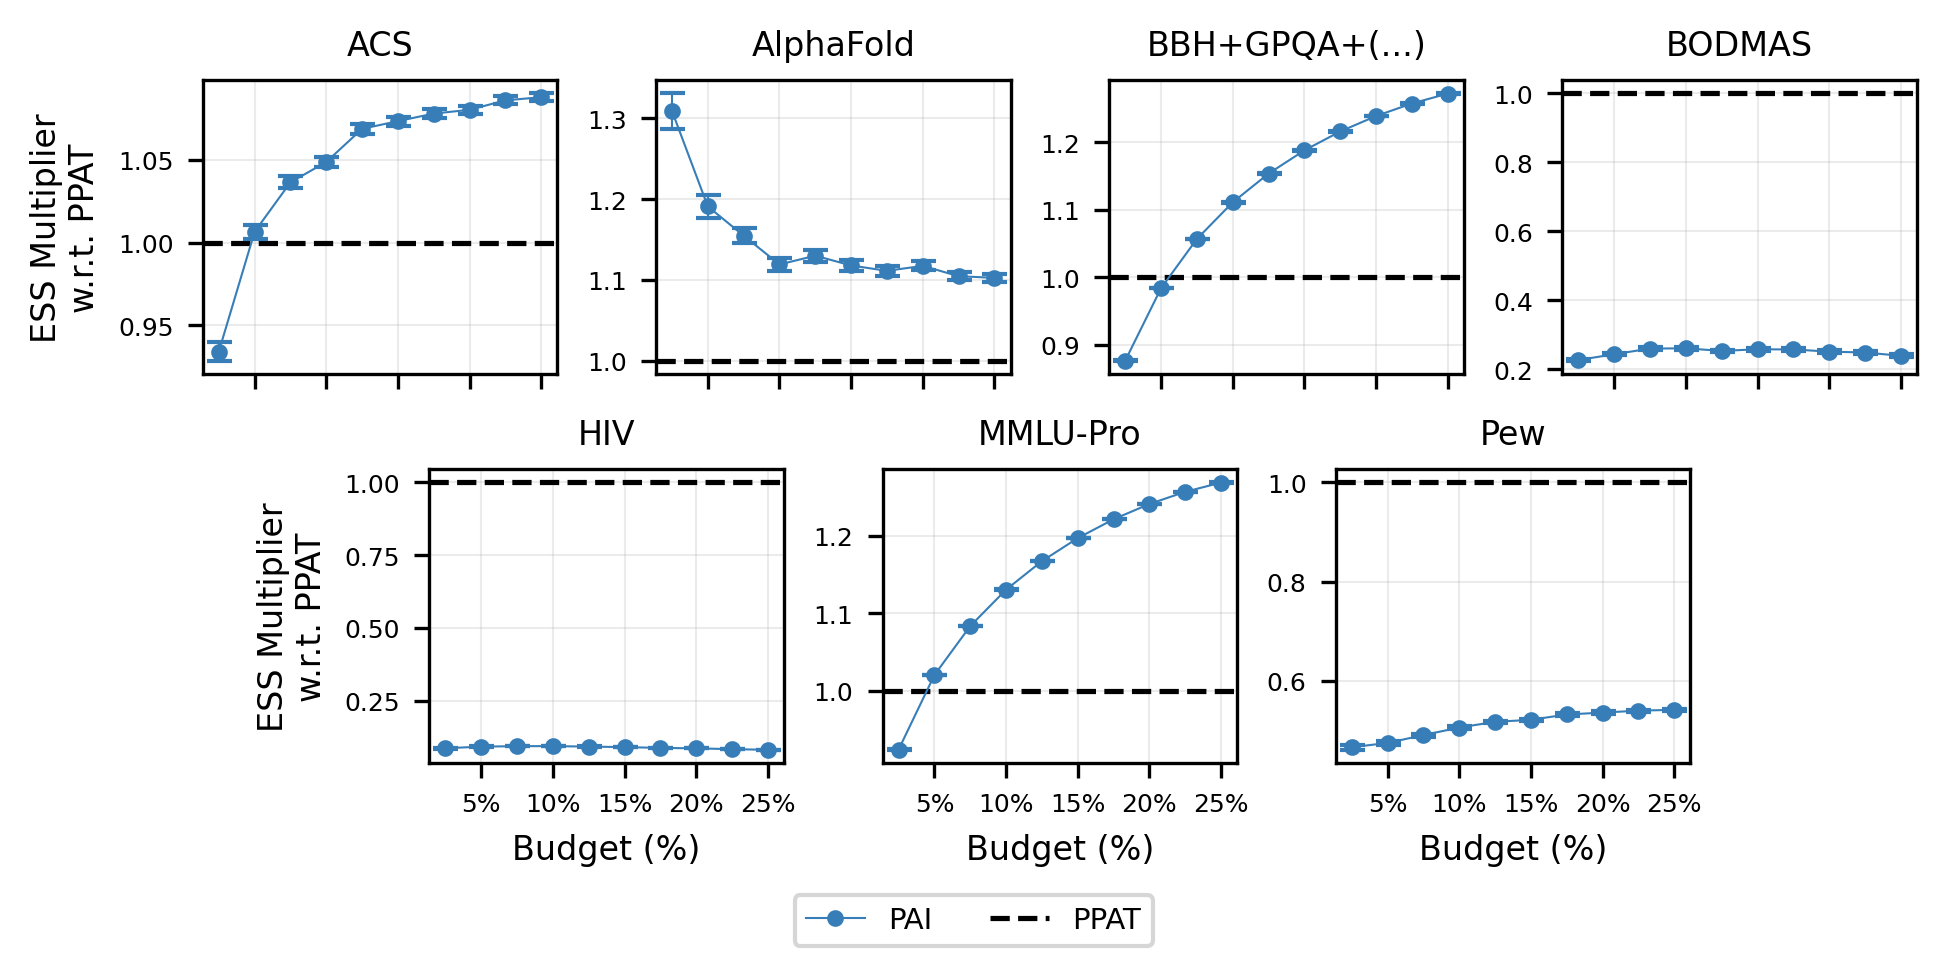

In [10]:
# load in the head-to-head with PPAT logs
ppat_summaries = pd.read_csv("summaries/ppat_comparison_summaries.csv")

'''
Note on ULB: coverage at 2.5% is 63.4% for PPAT, 64.6% for PAI, 
82.0% for SAI, 92.1% for PPI, and 92.1% for Uniform.
'''
# create a subplot grid for 7 of the 8 datasets
fig, axs = plt.subplot_mosaic(figsize=(6.5, 3), dpi=300, sharex=True,
    mosaic='''
    AABBCCDD
    .EEFFGG.
    '''
)

# go thru each of our non-DQ datasets and plot ESS multipliers
for i, ax_key in enumerate(axs.keys()):
    
    # grid it up for readability + say what dataset it is
    axs[ax_key].grid(alpha=0.25)
    axs[ax_key].set_title(dataset_descs[datasets[i]])
    if i > 3:
        axs[ax_key].set_xlabel("Budget (%)")
    if i == 0 or i == 4:
        axs[ax_key].set_ylabel("ESS Multiplier\nw.r.t. PPAT")
    
    # always need to put a red line for uniform would be
    axs[ax_key].axhline(y=1.0, linestyle="--", color="black", linewidth=1.25)
    
    # only need to plot relative ESS multiplier for PAI against PPAT
    q = ppat_summaries.query(f"dataset == '{datasets[i]}' and method == 'pai'")
    axs[ax_key].errorbar(
        q.budget, q.ess_multiplier_wrt_ppat_mean, yerr=q.ess_multiplier_wrt_ppat_sem,
        capsize=MARKERSIZE, capthick=1.0,
        marker=markers["pai"], color=colors["pai"])
    axs[ax_key].set_xticks([0.05, 0.10, 0.15, 0.20, 0.25])
    axs[ax_key].set_xticklabels(["5%", "10%", "15%", "20%", "25%"])
    
# custom legend
handles = [
    Line2D([], [], marker=markers["pai"], color=colors["pai"], label=method.upper())
    for method in ["pai"]
] + [Line2D([], [], linestyle="--", linewidth=1.25, color="black", label="PPAT")]
fig.legend(handles=handles, ncol=2, loc="lower center", bbox_to_anchor=(0.5, -0.07))
    
# beautify at the end
plt.tight_layout(w_pad=-2.0, h_pad=1.)
plt.savefig("figures/pai_vs_ppat_ess.pdf", facecolor="white", bbox_inches="tight")
plt.show()

# 5. Diagnostic for PAI vs. PPAT/PPI (Expected Brier Improvement; ECB).

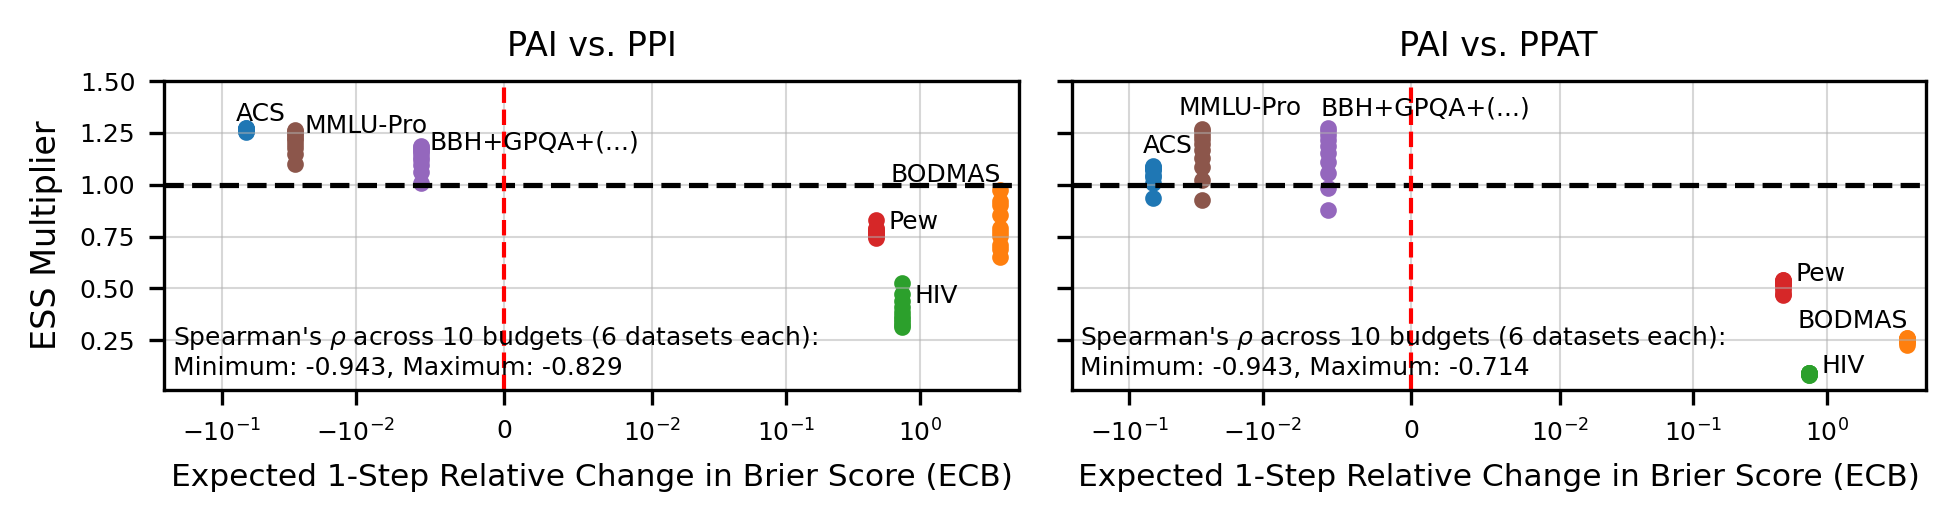

In [11]:
# plot expected brier improvement vs. ESS multipliers w.r.t. PPAT/PPI
fig, ax = plt.subplots(1, 2, figsize=(6.5, 1.75), dpi=300, sharex=True, sharey=True)

# load our shared diagnostic (EBI)
ebis = pd.read_csv("diagnostics/ppat_diagnostics_combined.csv")\
.replace("llm_evals/mmlu-pro", "mmlu-pro")\
.replace("llm_evals/bbh+gpqa+ifeval+math+musr", "bbh+gpqa+ifeval+math+musr")

#### 1. PPI diagnostic

# get our grids + labeled.
ax[0].grid(); ax[0].set_xlabel("Expected 1-Step Relative Change in Brier Score (ECB)", fontsize=MEDIUM_SIZE - 0.5)
ax[0].set_ylabel("ESS Multiplier")

# load in our logs
ppi_comparison_summaries = pd.read_csv("summaries/ppi_comparison_summaries.csv")

# storage
X_ppi, y_ppi = [], []

# go thru each dataset
for dataset in [d for d in ebis.dataset.unique() if d != "ulb"]:
    
    # a. EBI diagnostic + ESS multipliers
    ebi = ebis.query(f"dataset == '{dataset}'").post_mean_brier_im1_improvement.values
    ess_multipliers = ppi_comparison_summaries.query(
        f"dataset == '{dataset}' and method == 'pai'").ess_multiplier_wrt_ppi_mean.values
    
    # b. scatter plot EBI against ESS multipliers w.r.t. PPI + annotate
    ax[0].scatter([ebi[0]] * len(ess_multipliers), ess_multipliers)
    if dataset == "acs":
        delta_x, delta_y = 1.2, 0.04
    elif dataset == "mmlu-pro":
        delta_x, delta_y = 0.85, 0.0
    elif dataset == "bbh+gpqa+ifeval+math+musr":
        delta_x = 0.9; delta_y = 0.0
    elif dataset in ("pew", "hiv"):
        delta_x = 1.25; delta_y = 0.0
    elif dataset == "bodmas":
        delta_x, delta_y = 0.15, 0.12
    else:
        delta_x, delta_y = 1.1, 0.0
    ax[0].annotate(
        text=dataset_descs[dataset], 
        xy=(ebi[0] * delta_x, np.quantile(ess_multipliers, 0.75) + delta_y), fontsize=TICK_SIZE)
    
    # c. add to our list
    X_ppi.append([ebi[0]] * len(ess_multipliers))
    y_ppi.append(ess_multipliers)
    
# also compute some Spearman coefficients across budgets
X_ppi, y_ppi = np.array(X_ppi), np.array(y_ppi)
spearman_vals = sorted([spearmanr(X_ppi[:,i], y_ppi[:,i]).statistic for i in range(10)])

# annotate the spearman correlation ranges
r = "r"
ax[0].annotate(text=f"Spearman's $\{r}ho$ across 10 budgets (6 datasets each):\nMinimum: {np.min(spearman_vals):.3f}, " + \
            f"Maximum: {np.max(spearman_vals):.3f}",
            xy=(0.01, 0.05), xycoords="axes fraction", fontsize=TICK_SIZE)

# make a line where PPI and PAI are equal + set scale to symlog
ax[0].axhline(y=1.0, linestyle="--", color="black", linewidth=1.25)
ax[0].set_title("PAI vs. PPI")
ax[0].set_xscale("symlog", linthresh=0.01)
ax[0].set_ylim(top=1.4); ax[0].set_xlim(right=5.5)
ax[0].axvline(x=0.0, color="red", linestyle="--", linewidth=1.0)

#### 2. PPAT Diagnostic

# get our grids + labeled.
ax[1].grid(); ax[1].set_xlabel("Expected 1-Step Relative Change in Brier Score (ECB)", fontsize=MEDIUM_SIZE - 0.5)

# load in our logs
ppat_comparison_summaries = pd.read_csv("summaries/ppat_comparison_summaries.csv")

# storage
X_ppat, y_ppat = [], []

# go thru each dataset
for dataset in [d for d in ebis.dataset.unique() if d != "ulb"]:
    
    # a. EBI diagnostic + ESS multipliers
    ebi = ebis.query(f"dataset == '{dataset}'").post_mean_brier_im1_improvement.values
    ess_multipliers = ppat_comparison_summaries.query(
        f"dataset == '{dataset}' and method == 'pai'").ess_multiplier_wrt_ppat_mean.values
    
    # b. scatter plot EBI against ESS multipliers w.r.t. PPAT + annotate
    ax[1].scatter([ebi[0]] * len(ess_multipliers), ess_multipliers)
    if dataset == "acs":
        delta_x, delta_y = 1.2, 0.075
    elif dataset == "mmlu-pro":
        delta_x, delta_y = 1.5, 0.1
    elif dataset == "bbh+gpqa+ifeval+math+musr":
        delta_x = 1.1; delta_y = 0.1
    elif dataset in ("pew", "hiv"):
        delta_x = 1.25; delta_y = 0.0
    elif dataset == "bodmas":
        delta_x, delta_y = 0.15, 0.05
    else:
        delta_x, delta_y = 1.1, 0.0
    ax[1].annotate(
        text=dataset_descs[dataset], 
        xy=(ebi[0] * delta_x, np.quantile(ess_multipliers, 0.75) + delta_y), fontsize=TICK_SIZE)
    
    # c. add to our list
    X_ppat.append([ebi[0]] * len(ess_multipliers))
    y_ppat.append(ess_multipliers)
    
# also compute some Spearman coefficients across budgets
X_ppat, y_ppat = np.array(X_ppat), np.array(y_ppat)
spearman_vals = sorted([spearmanr(X_ppat[:,i], y_ppat[:,i]).statistic for i in range(10)])

# annotate the spearman correlation ranges
r = "r"
ax[1].annotate(text=f"Spearman's $\{r}ho$ across 10 budgets (6 datasets each):\nMinimum: {np.min(spearman_vals):.3f}, " + \
            f"Maximum: {np.max(spearman_vals):.3f}",
            xy=(0.01, 0.05), xycoords="axes fraction", fontsize=TICK_SIZE)

# make a line where PPAT and PAI are equal + set scale to symlog
ax[1].axhline(y=1.0, linestyle="--", color="black", linewidth=1.25)
ax[1].set_title("PAI vs. PPAT")
ax[1].set_xscale("symlog", linthresh=0.01)
ax[1].set_ylim(bottom=0.01, top=1.5); ax[0].set_xlim(right=5.5)
ax[1].axvline(x=0.0, color="red", linestyle="--", linewidth=1.0)

#### FINAL BEAUTIFYING
    
# beautify at the end
plt.tight_layout()
plt.savefig("figures/diagnosing_pai_vs_ppi-and-ppat.pdf", facecolor="white", bbox_inches="tight")
plt.show()

# 6. Diagnostic for PAI vs. Uniform (1-Step Residual Variance; IVR).

In [12]:
# load in the pai_vs_uniform diagnostics
rvs = pd.read_csv("diagnostics/unif_diagnostics.csv")\
.replace("llm_evals/mmlu-pro", "mmlu-pro")\
.replace("llm_evals/bbh+gpqa+ifeval+math+musr", "bbh+gpqa+ifeval+math+musr")

# also load in the original ESS multipliers vs. uniform
summaries = pd.read_csv("summaries/summaries.csv")

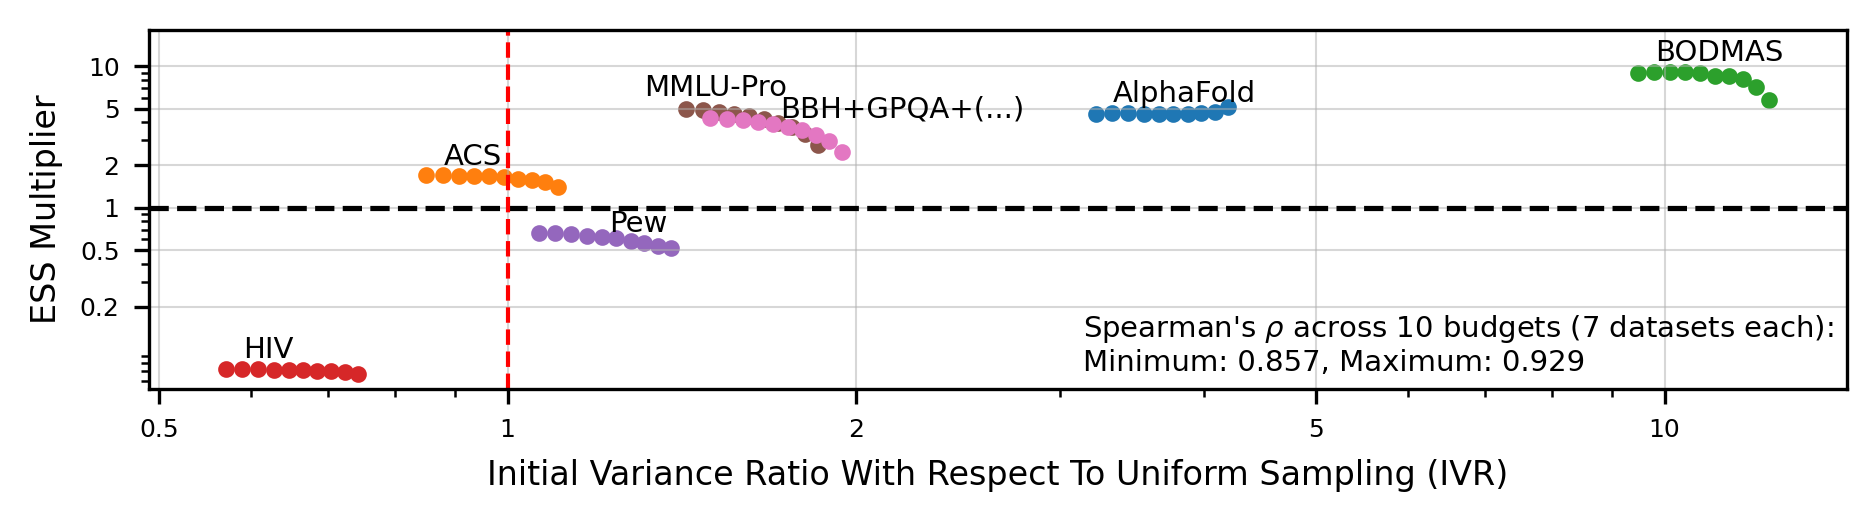

In [13]:
# we need to plot b2 vs. ESS multipliers vs. SAI
fig, ax = plt.subplots(figsize=(6.5, 1.75), dpi=300)
ax.grid()
ax.set_xlabel("Initial Variance Ratio With Respect To Uniform Sampling (IVR)"); ax.set_ylabel("ESS Multiplier")

# store the 1-step variance ratios and the corresponding ESS multipliers relative to uniform
X_rv, y_rv = [], []

# go thru all our datasets (except for ULB)
for dataset in [d for d in rvs.dataset.unique() if d != "ulb"]:
    
    # a. get the diagnostic for this dataset, at all the budgets
    rv_vals = rvs.query(f"dataset == '{dataset}'").sort_values(by="budget").R.values
    ess_multipliers = summaries.query(
        f"method == 'pai' and dataset == '{dataset}'").sort_values(by="budget").ess_multiplier_mean.values
    
    # b. scatter plot diagnostic against ESS multipliers w.r.t. Uniform + annotate
    ax.scatter(rv_vals, ess_multipliers)
    if dataset == "mmlu-pro":
        delta_x, delta_y = 0.8, 1.3
    elif dataset == "bbh+gpqa+ifeval+math+musr":
        delta_x, delta_y = 1.0, 1.05
    elif dataset == "pew":
        delta_x, delta_y = 1.0, 1.05
    else:
        delta_x, delta_y = 0.9, 1.2
    ax.annotate(text=dataset_descs[dataset], 
                xy=(rv_vals.mean() * delta_x, np.quantile(ess_multipliers, 0.75) * delta_y))
    
    # c. add to our list
    X_rv.append(rv_vals)
    y_rv.append(ess_multipliers)
    
# also compute some Spearman coefficients across budgets
X_rv, y_rv = np.array(X_rv), np.array(y_rv)
spearman_vals = sorted([spearmanr(X_rv[:,i], y_rv[:,i]).statistic for i in range(10)])
    
# annotate the spearman correlation ranges
r = "r"
ax.annotate(text=f"Spearman's $\{r}ho$ across 10 budgets (7 datasets each):\nMinimum: {np.min(spearman_vals):.3f}, " + \
            f"Maximum: {np.max(spearman_vals):.3f}", 
            xy=(0.55, 0.05), xycoords="axes fraction", fontsize=SMALL_SIZE)
    
# mark where the break-even point is
ax.axhline(y=1.0, linestyle="--", color="black", linewidth=1.25)
ax.axvline(x=1.0, color="red", linestyle="--", linewidth=1.0)

# beautify on the log-log scale because we are plotting ratios
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(top=18.0)
ax.set_xticks([0.5, 1, 2, 5, 10])
ax.set_yticks([0.2, 0.5, 1, 2, 5, 10])
ax.set_xticklabels([0.5, 1, 2, 5, 10])
ax.set_yticklabels([0.2, 0.5, 1, 2, 5, 10])

# final beautify + saving
plt.tight_layout()
plt.savefig("figures/diagnosing_pai_vs_uniform.pdf", facecolor="white", bbox_inches="tight")
plt.show()

# 7. Frozen-ML PAI ablation vs. PPAT/PPI/Uniform.

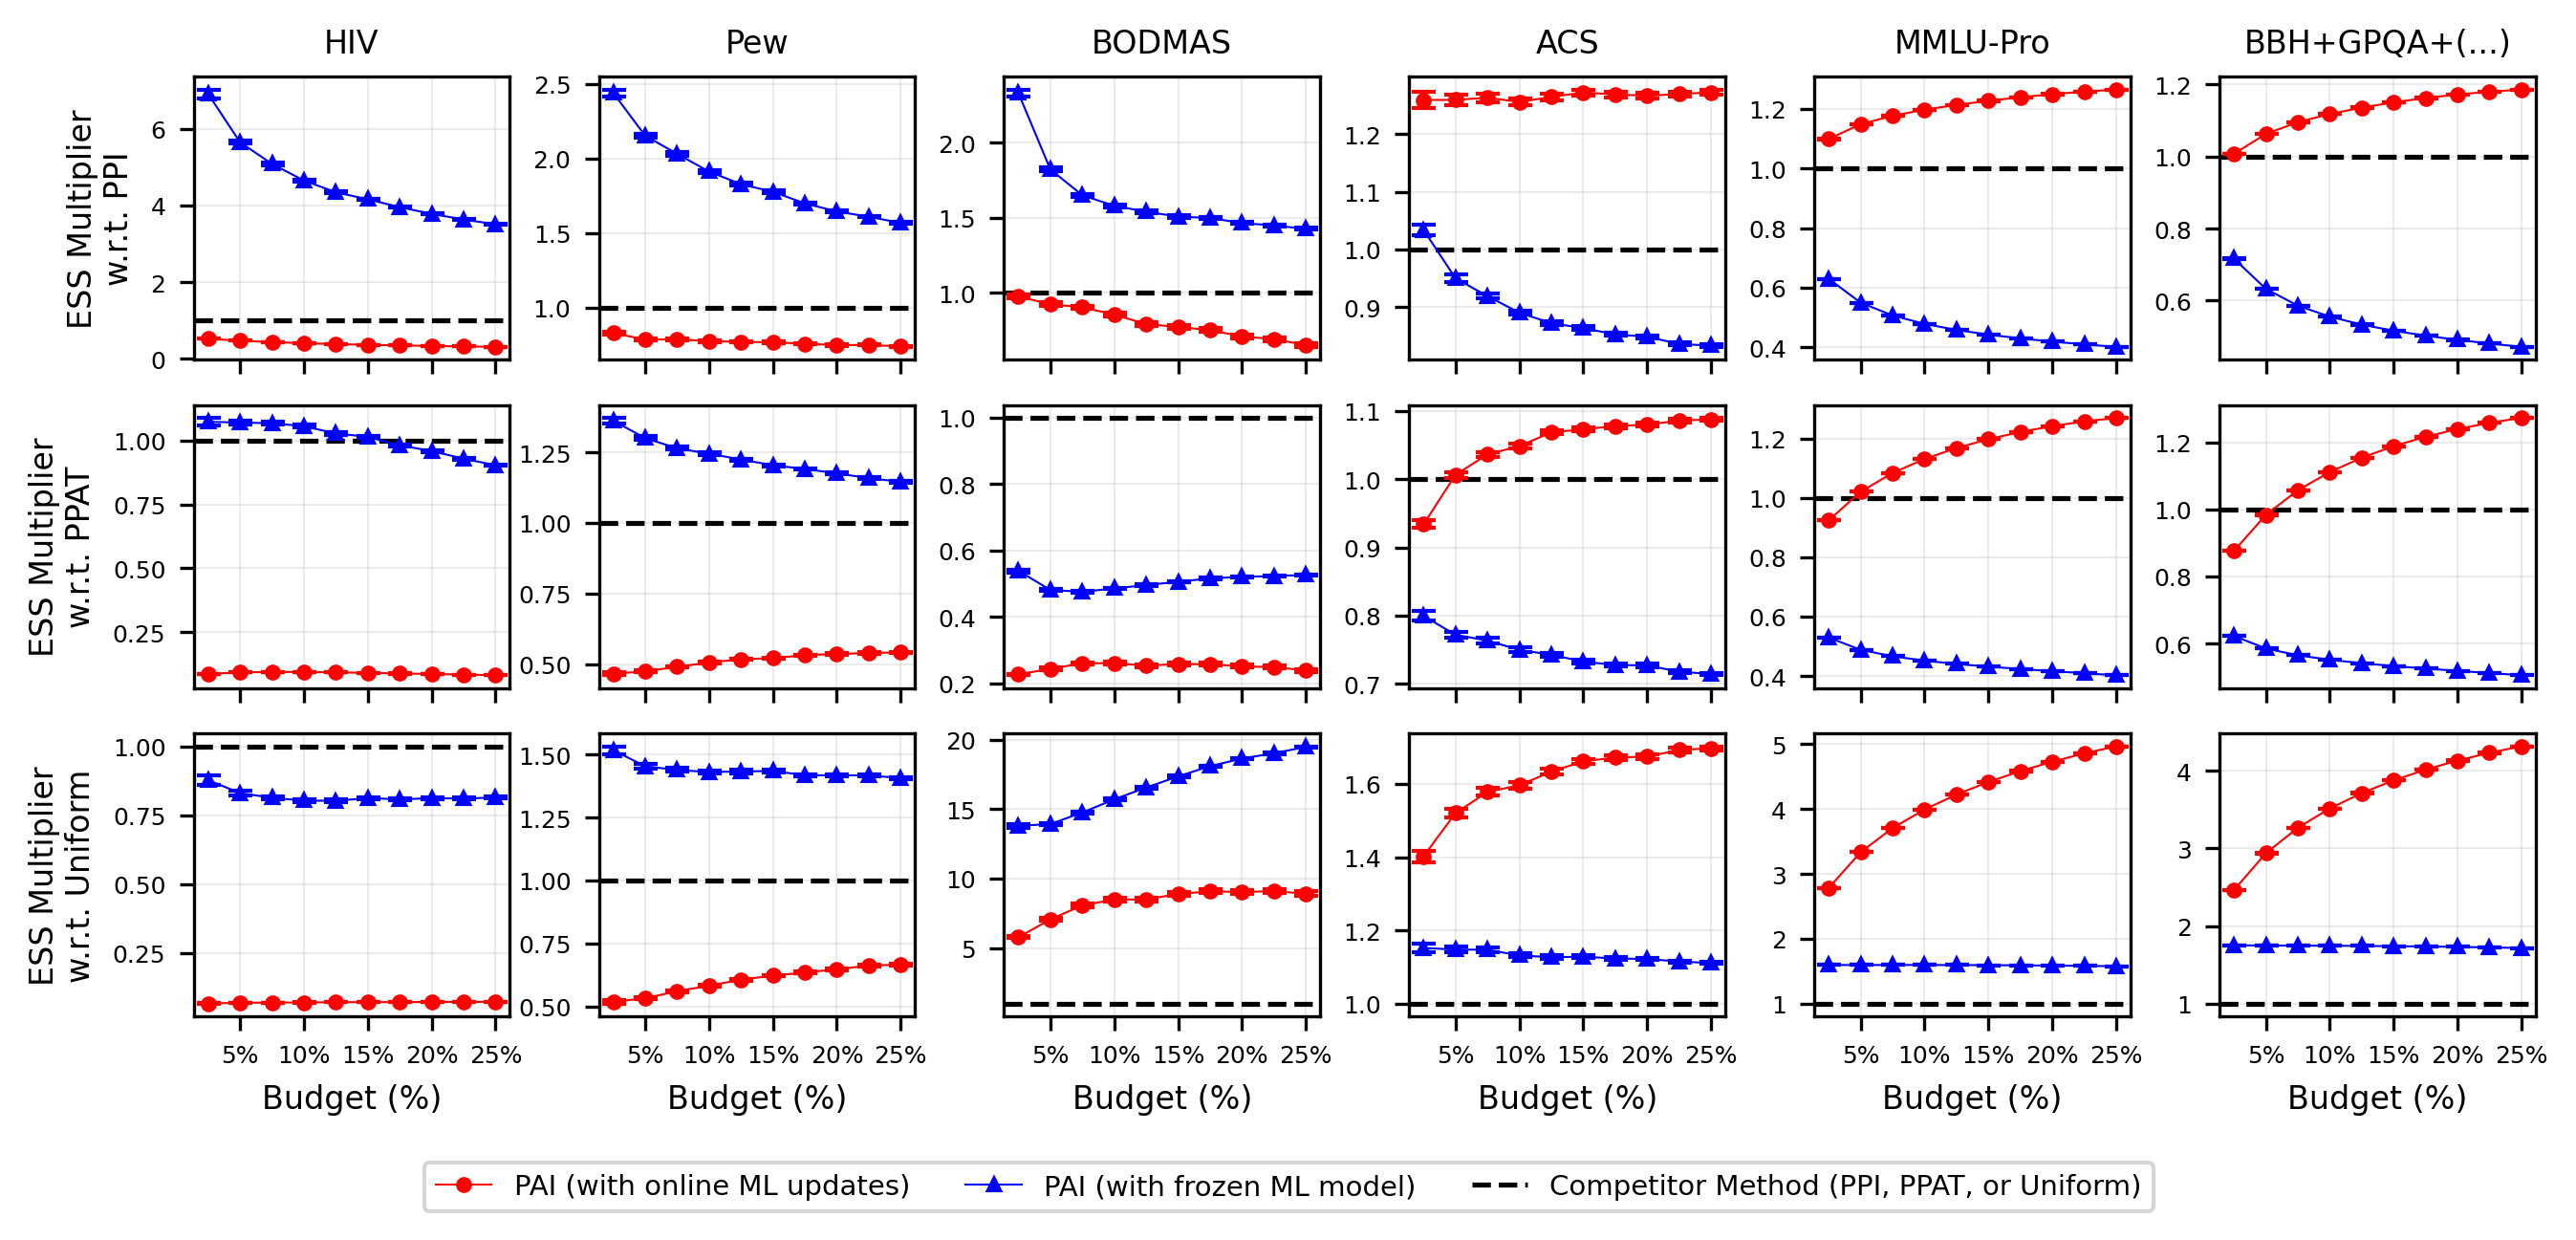

In [14]:
# how do results change when we freeze the ML model on the PAI ablation?
fig, ax = plt.subplots(3, 6, figsize=(9, 4), dpi=300, sharex=True)

# iterate thru each competitor method and iterate thru each dataset
for i, comp_method in enumerate(["ppi", "ppat", "unif"]):
    
    # load in the relevant summary
    comp_summaries = pd.read_csv(f"summaries/{comp_method}_comparison_summaries.csv")
    
    # iterate thru the relevant datasets (put the ones where we originally lost at the front)
    for j, dataset in enumerate(["hiv", "pew", "bodmas", "acs", "mmlu-pro", "bbh+gpqa+ifeval+math+musr"]):
        
        # beautify + label when appropriate
        if j == 0:
            method_desc = {"ppi" : "PPI", "ppat" : "PPAT", "unif" : "Uniform"}[comp_method]
            ax[i, j].set_ylabel(f"ESS Multiplier\nw.r.t. {method_desc}")
        if i == 0:
            ax[i, j].set_title(dataset_descs[dataset])
        if i == 2:
            ax[i, j].set_xlabel("Budget (%)")
        ax[i, j].set_xticks([0.05, 0.1, 0.15, 0.2, 0.25])
        ax[i, j].set_xticklabels(["5%", "10%", "15%", "20%", "25%"])
        ax[i, j].grid(alpha=0.25)
        
        # mark the break-even point
        ax[i, j].axhline(y=1.0, linestyle="--", color="black", linewidth=1.25)
        
        # get our queries
        q_pai = comp_summaries.query(f"method == 'pai' and dataset == '{dataset}'")
        q_pai_frozen = comp_summaries.query(f"method == 'pai_frozen' and dataset == '{dataset}'")
        ax[i, j].errorbar(
            q_pai.budget, 
            q_pai[f"ess_multiplier_wrt_{comp_method}_mean"], 
            capsize=MARKERSIZE, capthick=1.0, marker="o", color="red",
            yerr=q_pai[f"ess_multiplier_wrt_{comp_method}_sem"])
        ax[i, j].errorbar(
            q_pai_frozen.budget, 
            q_pai_frozen[f"ess_multiplier_wrt_{comp_method}_mean"], 
            capsize=MARKERSIZE, capthick=1.0, marker="^", color="blue",
            yerr=q_pai_frozen[f"ess_multiplier_wrt_{comp_method}_sem"])
    
# custom legend
handles = [
    Line2D([], [], marker="o", color="red", label="PAI (with online ML updates)"),
    Line2D([], [], marker="^", color="blue", label="PAI (with frozen ML model)"),
    Line2D([], [], linestyle="--", linewidth=1.25, color="black", label="Competitor Method (PPI, PPAT, or Uniform)")
]
fig.legend(handles=handles, ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.07))
    
# beautify at the end
plt.tight_layout(w_pad=-0.2, h_pad=1.)
plt.savefig("figures/pai-frozen-model-ablation_all-datasets.pdf", facecolor="white", bbox_inches="tight")
plt.show()